# 05 — Audit d'équité du modèle de retard par région

**Question** : le modèle de retard (notebook 04) traite-t-il de la même façon les clients de toutes les régions du Brésil ?

**Pourquoi c'est important** : le modèle utilise l'état du client, et les régions Norte et Nordeste sont en moyenne plus pauvres que le Sud-Est. Si les prédictions servaient à pénaliser des commandes (délai promis plus long, frais de port plus élevés, refus), un modèle qui signale davantage ces régions pénaliserait systématiquement des clients déjà moins favorisés.

Le code est dans `src/shoppulse/fairness.py` ; le pipeline d'entraînement régénère `docs/fairness_report.md` à chaque entraînement.

In [1]:
from typing import ClassVar

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from shoppulse.delay_model import (
    DelayMetrics,
    DelayModelFactory,
    DelayModelTrainer,
)
from shoppulse.fairness import (
    ALL_GROUPS,
    DelayFairnessAudit,
    FairnessAuditor,
)
from shoppulse.features import FEATURES, TARGET, DelayFeatureBuilder

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 160)

## 1. Les indicateurs

Le modèle signale une commande comme **à risque** quand sa probabilité dépasse le seuil retenu au notebook 04. Pour chaque région, on mesure :

| Indicateur | Question | Critère d'équité |
|---|---|---|
| **Taux de signalement** | quelle part des commandes est signalée ? | parité de traitement (règle des 4/5 : le ratio avec la référence doit rester entre 0,8 et 1,25) |
| **Rappel** | quelle part des vrais retards est détectée ? | égalité des chances : chaque région doit être aussi bien protégée |
| **Fausses alertes** | quelle part des commandes à l'heure est signalée à tort ? | même exposition aux erreurs |
| **Précision** | quand le modèle signale, a-t-il raison ? | même fiabilité du signal |
| **ROC-AUC** | le modèle classe-t-il bien à l'intérieur de la région ? | même qualité de service |

**Référence** : le Sudeste (68 % des commandes). Un écart de rappel ou de fausses alertes de plus de 10 points est jugé important. Certaines régions ont peu de retards (6 seulement pour le Norte sur le test) : chaque indicateur est donné avec un **intervalle de confiance à 95 %** (bootstrap), pour ne pas conclure sur du bruit.

In [2]:
frame = DelayFeatureBuilder().build()
results = DelayModelTrainer(frame).run()
audit = DelayFairnessAudit(results)
audits = audit.audits()
print(f"Modèle : {results.best_model}, seuil : {results.threshold:.3f}")
list(audits)

Modèle : gradient_boosting, seuil : 0.664


['Validation (06/2017 → 05/2018), seuil unique',
 'Test (06/2018 → 08/2018), seuil unique',
 'Test (06/2018 → 08/2018), seuils par région']

In [3]:
class FairnessChart:
    """Barres par région (signalement, rappel, fausses alertes) avec
    leurs intervalles de confiance."""

    LABELS: ClassVar[dict[str, str]] = {
        "flag_rate": "signalées", "tpr": "rappel", "fpr": "fausses alertes",
    }

    def __init__(self, auditor: FairnessAuditor) -> None:
        self.metrics = auditor.metrics().drop(index=ALL_GROUPS)
        self.intervals = auditor.intervals().drop(index=ALL_GROUPS)

    def plot(self, title: str) -> None:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
        for ax, (metric, label) in zip(axes, self.LABELS.items()):
            value = 100 * self.metrics[metric]
            low = 100 * self.intervals[f"{metric}_low"]
            high = 100 * self.intervals[f"{metric}_high"]
            colors = ["#1A1A17" if region == "Sudeste" else "#AA8350"
                      for region in value.index]
            ax.bar(value.index, value, color=colors,
                   yerr=[value - low, high - value], capsize=4)
            ax.set(title=label, ylabel="%")
            ax.tick_params(axis="x", rotation=30)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

## 2. Validation (juin 2017 → mai 2018)

Prédictions de la validation croisée temporelle : chaque commande est prédite par un modèle qui ne l'a jamais vue.

In [4]:
titles = list(audits)
validation = audits[titles[0]]
display(validation.metrics().round(3))
validation.disparities().round(2)

,orders,late_orders,late_rate,flag_rate,tpr,fpr,precision,roc_auc
customer_region,,,,,,,,
Centro-Oeste,3842,312,0.081,0.250,0.247,0.250,0.080,0.585
Nordeste,6086,970,0.159,0.528,0.678,0.499,0.205,0.609
Norte,1144,134,0.117,0.223,0.425,0.196,0.224,0.702
Sudeste,44303,3233,0.073,0.166,0.425,0.145,0.187,0.722
Sul,9290,702,0.076,0.254,0.397,0.242,0.118,0.643
Toutes,64665,5351,0.083,0.218,0.457,0.197,0.173,0.704


,flag_ratio,tpr_gap,fpr_gap,precision_gap,flag_ratio_ok,tpr_gap_ok,fpr_gap_ok
customer_region,,,,,,,
Centro-Oeste,1.51,-0.18,0.10,-0.11,False,False,False
Nordeste,3.18,0.25,0.35,0.02,False,False,False
Norte,1.35,0.00,0.05,0.04,False,True,True
Sudeste,1.00,0.00,0.00,0.00,True,True,True
Sul,1.53,-0.03,0.10,-0.07,False,True,True


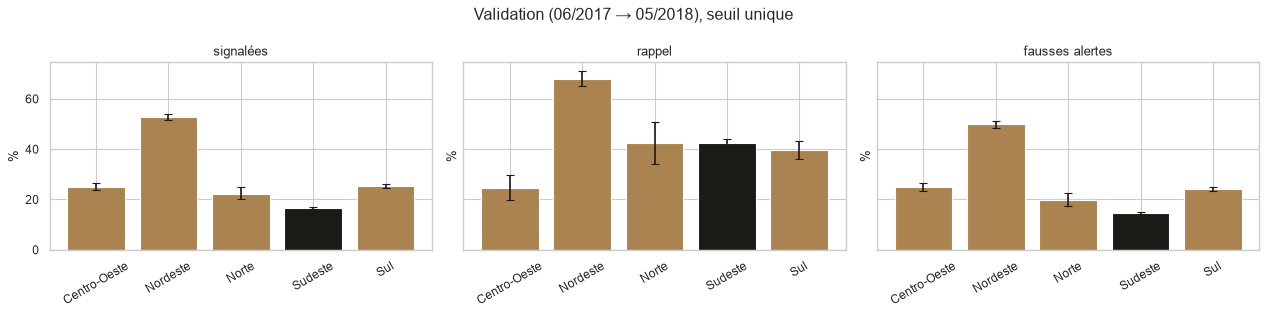

In [5]:
FairnessChart(validation).plot(titles[0])

**Lecture** : le Nordeste a deux fois plus de retards que le Sudeste (15,9 % contre 7,3 %), mais il est **signalé 3,2 fois plus** (53 % des commandes) : la moitié de ses commandes livrées à l'heure reçoivent une fausse alerte (50 % contre 15 %). À l'inverse, le Centro-Oeste est **moins bien protégé** : seulement 25 % de ses retards sont détectés, contre 43 % dans le Sudeste. La précision reste du même ordre partout : quand le modèle signale, il a à peu près autant raison. Enfin, le classement est moins bon dans le Centro-Oeste, le Nordeste et le Sul (ROC-AUC de 0,59 à 0,64 contre 0,72 dans le Sudeste), faute de données : 68 % des commandes d'apprentissage viennent du Sudeste.

## 3. Test (été 2018)

In [6]:
test = audits[titles[1]]
display(test.metrics().round(3))
test.disparities().round(2)

,orders,late_orders,late_rate,flag_rate,tpr,fpr,precision,roc_auc
customer_region,,,,,,,,
Centro-Oeste,1066,36,0.034,0.096,0.250,0.090,0.088,0.743
Nordeste,1640,78,0.048,0.564,0.731,0.556,0.062,0.636
Norte,301,6,0.020,0.365,0.667,0.359,0.036,0.708
Sudeste,13143,508,0.039,0.094,0.134,0.092,0.055,0.659
Sul,2453,44,0.018,0.062,0.136,0.060,0.040,0.645
Toutes,18603,672,0.036,0.136,0.214,0.133,0.057,0.651


,flag_ratio,tpr_gap,fpr_gap,precision_gap,flag_ratio_ok,tpr_gap_ok,fpr_gap_ok
customer_region,,,,,,,
Centro-Oeste,1.02,0.12,-0.00,0.03,True,False,True
Nordeste,6.00,0.60,0.46,0.01,False,False,False
Norte,3.89,0.53,0.27,-0.02,False,False,False
Sudeste,1.00,0.00,0.00,0.00,True,True,True
Sul,0.65,0.00,-0.03,-0.02,False,True,True


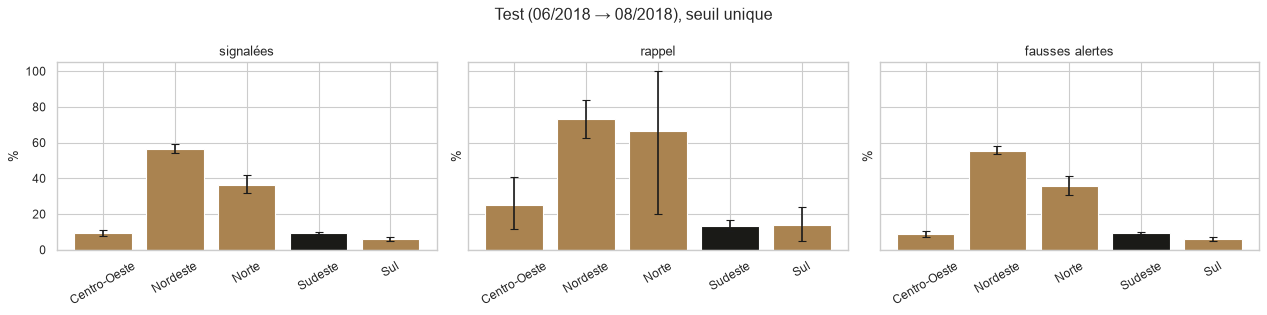

In [7]:
FairnessChart(test).plot(titles[1])

**Lecture** : avec la dérive de l'été 2018, les écarts **explosent**. Le Nordeste n'a presque plus de retards de plus que le Sudeste (4,8 % contre 3,9 %) mais **56 % de ses commandes sont signalées, contre 9 %** (ratio de 6). Le Norte, qui a moins de retards que le Sudeste, est signalé 4 fois plus. Et seulement **13 % des retards du Sudeste et du Sul** sont détectés. Le modèle a appris sur le passé que « Nordeste = risque » et continue à l'appliquer alors que ce n'est plus vrai. Pour le Norte (6 retards), les intervalles sont trop larges pour conclure sur le rappel.

## 4. Correction n° 1 : retirer l'état du client

Idée naïve : si le modèle ne « voit » pas la région, il ne peut pas discriminer. On réentraîne le même gradient boosting sans `customer_state`, avec la même validation croisée.

In [8]:
features = [column for column in FEATURES if column != "customer_state"]
unaware = DelayModelTrainer(frame, features=features)
unaware.candidates = {"sans_etat": DelayModelFactory.boosting()}
cv_unaware = DelayModelTrainer.summarize(unaware.cross_validate())
threshold_unaware = unaware.choose_threshold("sans_etat")
scores_unaware, predictions_unaware = unaware.evaluate_on_test(
    threshold_unaware, "sans_etat"
)
display(cv_unaware.round(3))
scores_unaware.round(3)

pr_auc        roc_auc        recall_top10        precision_top10       
            mean    std    mean    std         mean    std            mean    std
model                                                                            
sans_etat  0.174  0.109     0.7  0.042        0.259  0.056           0.207  0.139

,pr_auc,roc_auc,recall_top10,precision_top10,precision,recall,f1,balanced_accuracy,flagged_share
model,,,,,,,,,
sans_etat,0.06,0.636,0.167,0.06,0.071,0.109,0.086,0.528,0.055


In [9]:
unaware_audit = FairnessAuditor(predictions_unaware, "proba_sans_etat",
                                threshold_unaware)
comparison = pd.DataFrame({
    "ratio avec état": test.disparities()["flag_ratio"],
    "ratio sans état": unaware_audit.disparities()["flag_ratio"],
    "écart de rappel avec état": test.disparities()["tpr_gap"],
    "écart de rappel sans état": unaware_audit.disparities()["tpr_gap"],
})
comparison.round(2)

,ratio avec état,ratio sans état,écart de rappel avec état,écart de rappel sans état
customer_region,,,,
Centro-Oeste,1.02,3.15,0.12,0.19
Nordeste,6.00,15.97,0.60,0.49
Norte,3.89,11.95,0.53,0.47
Sudeste,1.00,1.00,0.00,0.00
Sul,0.65,1.15,0.00,0.06


**Lecture** : retirer l'état ne coûte presque rien en performance (PR-AUC moyenne de 0,174 contre 0,177 en validation) mais **ne corrige pas les écarts** : sur l'été 2018, l'écart de signalement est même plus fort (le Nordeste est signalé 16 fois plus que le Sudeste) et l'écart de rappel reste énorme (+49 points). Le modèle **retrouve la région par d'autres variables** : la distance, le délai habituel du trajet et la vitesse du réseau dépendent fortement de la géographie. Supprimer la variable sensible ne suffit pas quand d'autres variables jouent le rôle de **proxys** : c'est l'« équité par ignorance », reconnue comme inefficace.

## 5. Correction n° 2 : un seuil par région

On garde le modèle, mais on choisit **sur la validation** un seuil par région, de façon à ce que chaque région voie la même part de ses retards détectée que l'ensemble (46 %). C'est l'**égalité des chances** : chaque client en retard a la même probabilité d'être pris en charge, quelle que soit sa région.

In [10]:
thresholds = pd.Series(audit.region_thresholds.thresholds,
                       name="seuil par région")
print(f"Rappel visé : {audit.target_recall:.1%} ; "
      f"seuil global : {results.threshold:.3f}")
thresholds.round(3)

Rappel visé : 45.7% ; seuil global : 0.664


Centro-Oeste    0.563
Nordeste        0.752
Norte           0.638
Sudeste         0.638
Sul             0.637
Name: seuil par région, dtype: float64

In [11]:
adjusted = audits[titles[2]]
display(adjusted.metrics().round(3))
adjusted.disparities().round(2)

,orders,late_orders,late_rate,flag_rate,tpr,fpr,precision,roc_auc
customer_region,,,,,,,,
Centro-Oeste,1066,36,0.034,0.209,0.444,0.201,0.072,0.743
Nordeste,1640,78,0.048,0.362,0.577,0.351,0.076,0.636
Norte,301,6,0.020,0.409,0.667,0.403,0.033,0.708
Sudeste,13143,508,0.039,0.117,0.187,0.114,0.062,0.659
Sul,2453,44,0.018,0.089,0.159,0.088,0.032,0.645
Toutes,18603,672,0.036,0.145,0.249,0.141,0.062,0.651


,flag_ratio,tpr_gap,fpr_gap,precision_gap,flag_ratio_ok,tpr_gap_ok,fpr_gap_ok
customer_region,,,,,,,
Centro-Oeste,1.79,0.26,0.09,0.01,False,False,True
Nordeste,3.10,0.39,0.24,0.01,False,False,False
Norte,3.50,0.48,0.29,-0.03,False,False,False
Sudeste,1.00,0.00,0.00,0.00,True,True,True
Sul,0.76,-0.03,-0.03,-0.03,False,True,True


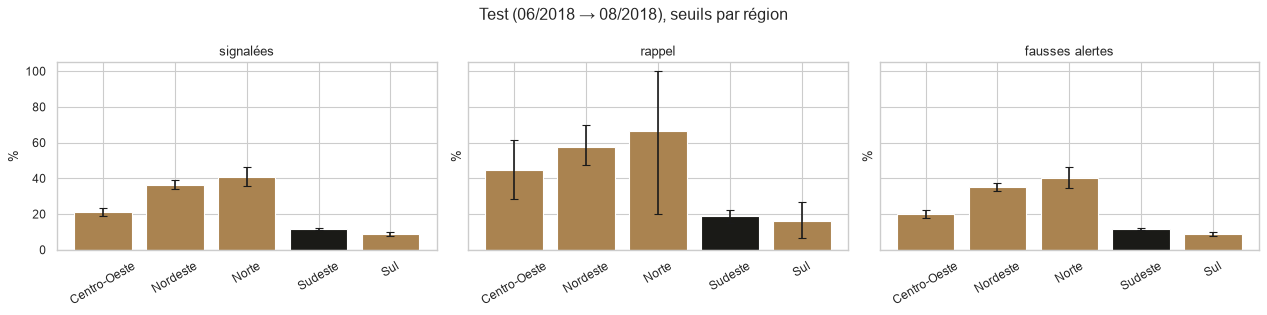

In [12]:
FairnessChart(adjusted).plot(titles[2])

In [13]:
score = results.test_predictions[audit.score_column].to_numpy()
y_test = results.test_predictions[TARGET].to_numpy()
row_thresholds = audit.region_thresholds.for_rows(
    results.test_predictions, results.threshold
)
pd.DataFrame({
    "seuil unique": DelayMetrics.at_threshold(y_test, score,
                                              results.threshold),
    "seuils par région": DelayMetrics.at_threshold(
        y_test, (score >= row_thresholds).astype(float), 0.5
    ),
}).round(3)

,seuil unique,seuils par région
precision,0.057,0.062
recall,0.214,0.249
f1,0.090,0.099
balanced_accuracy,0.541,0.554
flagged_share,0.136,0.145


**Lecture** : avec des seuils par région, le modèle est **à la fois plus performant et plus équitable** sur l'été 2018 : rappel global de 25 % au lieu de 21 %, précision de 6,2 % au lieu de 5,7 %, et le Nordeste n'est plus signalé que 3 fois plus que le Sudeste (au lieu de 6). Les écarts ne disparaissent pas : les seuils sont calibrés sur le passé et la dérive les rend imparfaits (le Centro-Oeste est maintenant davantage signalé). Il faut donc **les recalibrer à chaque réentraînement** ; le pipeline le fait et les enregistre avec le modèle.

## 6. Conclusions et recommandations

1. **Constat** : le modèle signale beaucoup selon la région. Le Nordeste est sur-signalé (fausses alertes multipliées par 3 à 6), le Sudeste et le Sul sont sous-protégés sur l'été 2018. La précision, elle, est comparable entre régions.
2. **Origine** : le passé (le Nordeste avait deux fois plus de retards), la dérive de l'été 2018, et moins de données hors du Sudeste.
3. **Retirer l'état du client ne suffit pas** : la géographie passe par la distance et le trajet.
4. **Seuils par région** recalibrés à chaque entraînement : meilleure performance et écarts réduits ; c'est la règle recommandée pour l'API.
5. **Usage autorisé** : actions **bénéfiques** pour le client (surveiller la commande, le prévenir, offrir un geste commercial). Une fausse alerte coûte alors un message inutile.
6. **Usage interdit** : toute décision **pénalisante** fondée sur le score (allonger le délai promis, augmenter les frais de port, refuser une commande, déclasser un vendeur) : elle frapperait d'abord les régions les plus pauvres.
7. **Suivi** : `docs/fairness_report.md` est régénéré à chaque entraînement ; tout ratio de signalement hors de la règle des 4/5 doit être examiné avant de mettre un nouveau modèle en service.

Ces points sont repris dans la note éthique (`docs/ethique.md`).